# Sagittarius Catalog and Gaia XP Data Acquisition

Cleaned PS4 version of the catalog workflow. It saves generated files under `data/`, records matching results, supports resumable Gaia XP downloads, combines batch files, and produces a summary for `report_ps4.pdf`.


## 1. Imports and paths


In [6]:
from pathlib import Path
import gc
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from astropy.table import Table, vstack
from astroquery.gaia import Gaia
from astroquery.vizier import Vizier
from tqdm.auto import tqdm

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "src":
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_DIR = PROJECT_ROOT / "data"
XP_BATCH_DIR = DATA_DIR / "Vasiliev_Sgr_XP_batches"
DATA_DIR.mkdir(parents=True, exist_ok=True)
XP_BATCH_DIR.mkdir(parents=True, exist_ok=True)

BATCH_SIZE = 25
MIN_BATCH_SIZE = 5
MAX_RETRIES = 3
PAUSE_SECONDS = 2
print("Project root:", PROJECT_ROOT)
print("Data directory:", DATA_DIR)


Project root: /Users/hmorg/CS4425/group
Data directory: /Users/hmorg/CS4425/group/data


## 2. Retrieve and save the Vasiliev Sagittarius catalog


In [9]:
from io import StringIO
from astropy.table import Table
import numpy as np
import pandas as pd


def read_vizier_tsv(path):
    """
    Read a VizieR ASU-TSV file while ignoring metadata, units,
    separator rows, and incomplete records.
    """
    with open(path, "r", encoding="utf-8", errors="replace") as file:
        lines = file.readlines()

    # Remove VizieR metadata and blank lines.
    content_lines = [
        line for line in lines
        if line.strip() and not line.startswith("#")
    ]

    if len(content_lines) < 4:
        raise RuntimeError(f"No usable table was found in {path}")

    # The first non-comment line contains the column names.
    header = content_lines[0]

    # Keep only rows whose first tab-separated field is a record number.
    data_lines = []

    for line in content_lines[1:]:
        first_field = line.split("\t", maxsplit=1)[0].strip()

        if first_field.isdigit():
            data_lines.append(line)

    cleaned_text = header + "".join(data_lines)

    dataframe = pd.read_csv(
        StringIO(cleaned_text),
        sep="\t",
        dtype=str
    )

    dataframe.columns = [
        str(column).strip()
        for column in dataframe.columns
    ]

    if "recno" not in dataframe.columns:
        raise RuntimeError(
            f"The recno column was not found in {path}. "
            f"Columns found: {dataframe.columns.tolist()}"
        )

    dataframe["recno"] = pd.to_numeric(
        dataframe["recno"],
        errors="coerce"
    )

    dataframe = dataframe.dropna(
        subset=["recno"]
    ).copy()

    dataframe["recno"] = dataframe["recno"].astype(np.int64)

    return dataframe


fits_path = DATA_DIR / "vasiliev_sgr.fits"
main_path = DATA_DIR / "vasiliev_sgr.tsv"
tail_path = DATA_DIR / "vasiliev_sgr_tail.tsv"


if fits_path.exists():
    print("Loading local FITS catalog:", fits_path)

    sgr = Table.read(fits_path)

elif main_path.exists() and tail_path.exists():
    print("Loading downloaded VizieR TSV files...")

    main_df = read_vizier_tsv(main_path)
    tail_df = read_vizier_tsv(tail_path)

    print("Complete records in main file:", len(main_df))
    print("Complete records in tail file:", len(tail_df))
    print(
        "Main record range:",
        main_df["recno"].min(),
        "through",
        main_df["recno"].max()
    )
    print(
        "Tail record range:",
        tail_df["recno"].min(),
        "through",
        tail_df["recno"].max()
    )

    # The original file was interrupted while transferring record 55148.
    # Keep its complete rows below that record and use the tail download
    # for records 55148 through 55192.
    main_df = main_df[
        main_df["recno"] < 55148
    ].copy()

    combined_df = pd.concat(
        [main_df, tail_df],
        ignore_index=True
    )

    combined_df = (
        combined_df
        .drop_duplicates(subset="recno", keep="last")
        .sort_values("recno")
        .reset_index(drop=True)
    )

    expected_records = set(range(1, 55193))
    actual_records = set(combined_df["recno"].tolist())
    missing_records = sorted(expected_records - actual_records)

    print("Combined catalog rows:", len(combined_df))
    print("Missing record numbers:", len(missing_records))

    if missing_records:
        print("First missing records:", missing_records[:20])

        raise RuntimeError(
            "The combined catalog is still incomplete. "
            f"{len(missing_records)} record(s) are missing."
        )

    if len(combined_df) != 55192:
        raise RuntimeError(
            f"Expected 55,192 rows but found {len(combined_df):,}."
        )

    sgr = Table.from_pandas(
        combined_df,
        index=False
    )

    sgr.write(
        fits_path,
        format="fits",
        overwrite=True
    )

    print("Saved complete FITS catalog:", fits_path)

else:
    raise FileNotFoundError(
        "The local FITS file or the two TSV files are missing."
    )


sgr_df = sgr.to_pandas()

sgr_df.to_csv(
    DATA_DIR / "vasiliev_sgr.csv",
    index=False
)

print("Catalog rows:", len(sgr_df))
print("Columns:", sgr.colnames)

sgr[:5]

Loading downloaded VizieR TSV files...
Complete records in main file: 55148
Complete records in tail file: 45
Main record range: 1 through 55148
Tail record range: 55148 through 55192
Combined catalog rows: 55192
Missing record numbers: 0


Saved complete FITS catalog: /Users/hmorg/CS4425/group/data/vasiliev_sgr.fits
Catalog rows: 55192
Columns: ['recno', 'RAJ2000', 'DEJ2000', 'plx', 'e_plx', 'pmRA', 'e_pmRA', 'pmDE', 'e_pmDE', 'Gmag', 'BPmag', 'Jmag', 'Hmag', 'Kmag', 'E(B-V)', 'Dist', 'e_Dist', 'vLOS', 'e_vLOS', '[Fe/H]', 'e_[Fe/H]', 'Ref', 'Lambda', 'Beta', 'SimbadName']


recno,RAJ2000,DEJ2000,plx,e_plx,pmRA,e_pmRA,pmDE,e_pmDE,Gmag,BPmag,Jmag,Hmag,Kmag,E(B-V),Dist,e_Dist,vLOS,e_vLOS,[Fe/H],e_[Fe/H],Ref,Lambda,Beta,SimbadName
int64,str8,str8,str6,str6,str6,str6,str6,str6,str5,str5,str5,str5,str5,str5,str5,str5,str7,str5,str5,str5,str1,str8,str7,str28
1,000.0357,-10.4442,-0.075,0.099,-1.627,0.125,-3.325,0.093,16.13,1.32,14.46,13.80,13.73,0.04,21.03,1.47,,,,,0,-72.652,-6.886,Gaia DR2 2422822873087610624
2,000.0628,-23.6540,0.050,0.048,-1.148,0.072,-2.844,0.053,15.04,1.40,13.26,12.62,12.48,0.02,23.63,3.93,,,,,0,-67.073,5.093,Gaia DR2 2339739994921350912
3,000.0737,-23.3191,0.045,0.049,-2.548,0.105,-4.186,0.058,15.55,1.25,13.98,13.38,13.28,0.02,22.73,4.04,,,,,0,-67.225,4.794,Gaia DR2 2339854378490321280
4,000.0851,-19.3309,0.022,0.045,-1.882,0.084,-3.660,0.049,15.56,1.47,13.75,13.05,12.92,0.02,22.82,0.58,,,,,0,-68.925,1.186,Gaia DR2 2413932084626466432
5,000.1081,-13.8471,0.098,0.043,-1.129,0.075,-3.148,0.046,14.97,1.50,13.13,12.38,12.27,0.04,22.35,3.30,,,,,0,-71.266,-3.774,Gaia DR2 2420742906325713536


## 3. Extract Gaia DR2 identifiers


In [11]:
if "SimbadName" not in sgr_df.columns:
    raise KeyError(
        "Expected SimbadName column was not found. "
        f"Available columns: {sgr_df.columns.tolist()}"
    )

# Extract the numeric portion from values such as:
# Gaia DR2 2422822873087610624
extracted_ids = (
    sgr_df["SimbadName"]
    .astype("string")
    .str.extract(r"Gaia DR2\s+(\d+)", expand=False)
)

# Convert the entire result to pandas nullable 64-bit integers.
# Missing or malformed IDs become <NA>.
sgr_df["dr2_source_id"] = pd.to_numeric(
    extracted_ids,
    errors="coerce"
).astype("Int64")

valid_dr2 = sgr_df["dr2_source_id"].notna()

print("Total catalog rows:", len(sgr_df))
print("Stars with DR2 IDs:", int(valid_dr2.sum()))
print("Stars without DR2 IDs:", int((~valid_dr2).sum()))

# Save the catalog with the extracted identifier column.
sgr_df.to_csv(
    DATA_DIR / "vasiliev_sgr_with_dr2_ids.csv",
    index=False
)

# Remove missing IDs before converting to NumPy int64.
dr2_ids = (
    sgr_df.loc[valid_dr2, "dr2_source_id"]
    .astype(np.int64)
    .drop_duplicates()
    .to_numpy(dtype=np.int64)
)

upload_table = Table({
    "dr2_source_id": dr2_ids
})

print("Unique DR2 IDs:", len(dr2_ids))

upload_table[:5]

Total catalog rows: 55192
Stars with DR2 IDs: 55192
Stars without DR2 IDs: 0
Unique DR2 IDs: 55192


dr2_source_id
int64
2422822873087610624
2339739994921350912
2339854378490321280
2413932084626466432
2420742906325713536


## 4. Match Gaia DR2 to Gaia DR3


In [12]:
query = """
SELECT u.dr2_source_id, n.dr3_source_id, n.angular_distance,
       n.magnitude_difference, g.ra, g.dec, g.phot_g_mean_mag,
       g.phot_bp_mean_mag, g.phot_rp_mean_mag, g.bp_rp, g.ruwe,
       g.has_xp_continuous, g.has_xp_sampled
FROM tap_upload.sgr_dr2 AS u
JOIN gaiadr3.dr2_neighbourhood AS n
  ON u.dr2_source_id = n.dr2_source_id
JOIN gaiadr3.gaia_source AS g
  ON n.dr3_source_id = g.source_id
"""
job = Gaia.launch_job_async(
    query, upload_resource=upload_table,
    upload_table_name="sgr_dr2", verbose=True
)
dr2_dr3 = job.get_results()
match_df = dr2_dr3.to_pandas()
match_counts = match_df.groupby("dr2_source_id").size().rename("n_dr3_matches")
match_df = match_df.merge(match_counts, on="dr2_source_id", how="left")
unique_matches = match_df[match_df["n_dr3_matches"] == 1].copy()
ambiguous_matches = match_df[match_df["n_dr3_matches"] > 1].copy()

match_df.to_csv(DATA_DIR / "sgr_dr2_dr3_all_matches.csv", index=False)
unique_matches.to_csv(DATA_DIR / "sgr_dr2_dr3_unique_matches.csv", index=False)
ambiguous_matches.to_csv(DATA_DIR / "sgr_dr2_dr3_ambiguous_matches.csv", index=False)
print("Exactly one candidate:", int((match_counts == 1).sum()))
print("Multiple candidates:", int((match_counts > 1).sum()))


Launched query: '
SELECT u.dr2_source_id, n.dr3_source_id, n.angular_distance,
       n.magnitude_difference, g.ra, g.dec, g.phot_g_mean_mag,
       g.phot_bp_mean_mag, g.phot_rp_mean_mag, g.bp_rp, g.ruwe,
       g.has_xp_continuous, g.has_xp_sampled
FROM tap_upload.sgr_dr2 AS u
JOIN gaiadr3.dr2_neighbourhood AS n
  ON u.dr2_source_id = n.dr2_source_id
JOIN gaiadr3.gaia_source AS g
  ON n.dr3_source_id = g.source_id
'
------>https
host = gea.esac.esa.int:443
context = /tap-server/tap/async
Content-type = multipart/form-data; boundary====1793846196483===
303 303
[('Date', 'Thu, 05 Nov 2026 02:36:37 GMT'), ('Server', 'Apache/2.4.62 (Red Hat Enterprise Linux) OpenSSL/3.5.5 mod_jk/1.2.50'), ('Set-Cookie', 'JSESSIONID=62C0BB3B206222ED996EA4AD64B48133; Path=/tap-server; Secure; HttpOnly'), ('Location', 'https://gea.esac.esa.int/tap-server/tap/async/b963d1bb-d8c1-11f1-b71e-bc97e148b76b-O'), ('X-Content-Type-Options', 'nosniff'), ('X-XSS-Protection', '0'), ('Cache-Control', 'no-cache, no-store

## 5. Inspect ambiguous matches


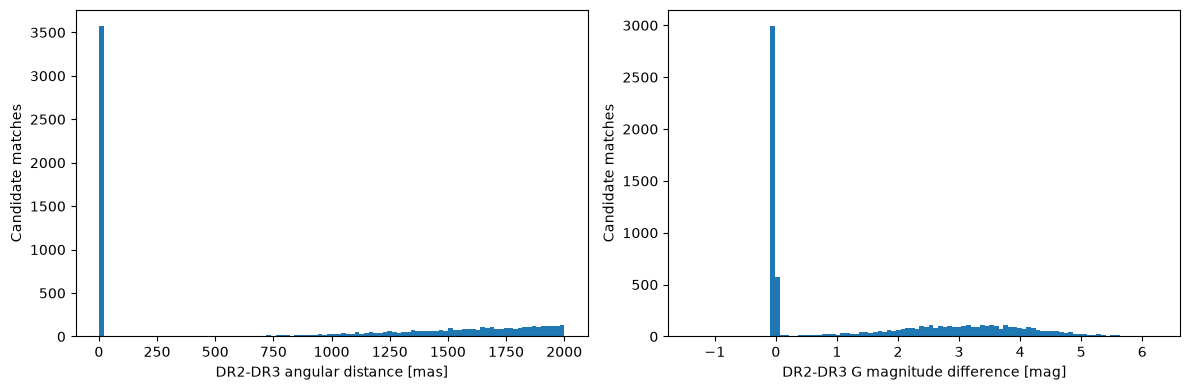

In [13]:
if len(ambiguous_matches):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].hist(ambiguous_matches["angular_distance"].dropna(), bins=100)
    axes[0].set(xlabel="DR2-DR3 angular distance [mas]", ylabel="Candidate matches")
    axes[1].hist(ambiguous_matches["magnitude_difference"].dropna(), bins=100)
    axes[1].set(xlabel="DR2-DR3 G magnitude difference [mag]", ylabel="Candidate matches")
    plt.tight_layout()
    plt.show()
else:
    print("No ambiguous matches were returned.")


## 6. Select sources with XP continuous spectra


In [19]:
unique_matches["has_xp_continuous"] = (
    unique_matches["has_xp_continuous"]
    .fillna(False)
    .astype(bool)
)

xp_matches = unique_matches[
    unique_matches["has_xp_continuous"]
].copy()

xp_matches.to_csv(
    DATA_DIR / "sgr_dr3_xp_matches.csv",
    index=False
)

xp_ids = (
    xp_matches["dr3_source_id"]
    .astype(np.int64)
    .drop_duplicates()
    .to_numpy()
)

xp_source_list = pd.DataFrame({
    "source_id": xp_ids,
    "chunk": np.arange(len(xp_ids)) // 5000
})

xp_source_list.to_csv(
    DATA_DIR / "sgr_xp_source_ids.csv",
    index=False
)

print("Unambiguous DR3 matches:", len(unique_matches))
print("Sources with XP continuous spectra:", len(xp_ids))
print(
    "XP availability percentage:",
    f"{100 * len(xp_ids) / len(unique_matches):.2f}%"
)

Unambiguous DR3 matches: 42386
Sources with XP continuous spectra: 27069
XP availability percentage: 63.86%


## 7. Resumable XP download helpers


In [26]:
def convert_gaia_table(obj):
    if isinstance(obj, Table):
        return obj
    if hasattr(obj, "to_table"):
        return obj.to_table(use_names_over_ids=True)
    if hasattr(obj, "array"):
        return Table(obj.array)
    return Table(obj)


def retrieve_xp(ids):
    """
    Retrieve Gaia DR3 XP continuous coefficients for source IDs.
    """
    ids = np.asarray(ids, dtype=np.int64)

    result = Gaia.load_data(
        ids=ids.tolist(),
        data_release="Gaia DR3",
        retrieval_type="XP_CONTINUOUS",
        data_structure="DATAMODEL_GAIA",
        format="votable",
        verbose=False
    )

    tables = []

    for objects in result.values():
        for obj in objects:
            table = convert_gaia_table(obj)

            if len(table) > 0 and "source_id" in table.colnames:
                tables.append(table)

    if not tables:
        raise RuntimeError(
            "Gaia returned no XP table containing source_id."
        )

    if len(tables) == 1:
        return tables[0]

    return vstack(
        tables,
        metadata_conflicts="silent"
    )


def get_already_downloaded():
    downloaded = set()
    for file in XP_BATCH_DIR.glob("xp_*.fits"):
        try:
            table = Table.read(file)
            if "source_id" in table.colnames:
                downloaded.update(int(x) for x in table["source_id"])
        except Exception as exc:
            print(f"WARNING: could not read {file.name}: {exc}")
    return downloaded


def save_xp_table(table):
    ids = np.unique(np.asarray(table["source_id"], dtype=np.int64))
    path = XP_BATCH_DIR / f"xp_{ids.min()}_{ids.max()}_{len(ids)}.fits"
    table.write(path, format="fits", overwrite=True)
    return path


In [29]:
failed_ids = []

def download_group(ids, pbar, depth=0):
    ids = np.asarray(ids, dtype=np.int64)
    if not len(ids):
        return
    indent = "    " * depth
    for attempt in range(1, MAX_RETRIES + 1):
        try:
            table = retrieve_xp(ids)
            path = save_xp_table(table)
            returned = set(int(x) for x in np.asarray(table["source_id"], dtype=np.int64))
            missing = np.asarray([x for x in ids if int(x) not in returned], dtype=np.int64)
            pbar.update(len(returned))
            tqdm.write(f"{indent}Saved {len(returned)}/{len(ids)} to {path.name}")
            if len(missing):
                download_group(missing, pbar, depth + 1)
            gc.collect()
            time.sleep(PAUSE_SECONDS)
            return
        except Exception as exc:
            tqdm.write(f"{indent}Attempt {attempt}/{MAX_RETRIES} failed: {exc}")
            if attempt < MAX_RETRIES:
                time.sleep(5 * attempt)
    if len(ids) > MIN_BATCH_SIZE:
        middle = len(ids) // 2
        download_group(ids[:middle], pbar, depth + 1)
        download_group(ids[middle:], pbar, depth + 1)
    else:
        failed_ids.extend(int(x) for x in ids)


In [17]:
matched_dr2_ids = match_df["dr2_source_id"].nunique()
unmatched_dr2_ids = len(dr2_ids) - matched_dr2_ids

print("Input DR2 IDs:", len(dr2_ids))
print("DR2 IDs with at least one DR3 candidate:", matched_dr2_ids)
print("DR2 IDs with exactly one candidate:", int((match_counts == 1).sum()))
print("DR2 IDs with multiple candidates:", int((match_counts > 1).sum()))
print("DR2 IDs without a returned candidate:", unmatched_dr2_ids)

Input DR2 IDs: 55192
DR2 IDs with at least one DR3 candidate: 46014
DR2 IDs with exactly one candidate: 42386
DR2 IDs with multiple candidates: 3628
DR2 IDs without a returned candidate: 9178


In [24]:
already_downloaded = get_already_downloaded()

remaining_ids = np.asarray(
    [
        sid
        for sid in xp_ids
        if int(sid) not in already_downloaded
    ],
    dtype=np.int64
)

print(
    "Existing FITS batch files:",
    len(list(XP_BATCH_DIR.glob("xp_*.fits")))
)

print(
    "Unique source IDs already downloaded:",
    len(already_downloaded)
)

print(
    "Total XP targets:",
    len(xp_ids)
)

print(
    "Remaining targets:",
    len(remaining_ids)
)

Existing FITS batch files: 13
Unique source IDs already downloaded: 550
Total XP targets: 27069
Remaining targets: 26519


## 8. Run the resumable XP download


In [27]:
test_id = np.asarray([xp_ids[0]], dtype=np.int64)

test_table = retrieve_xp(test_id)

print("Returned rows:", len(test_table))
print("Columns:")
print(test_table.colnames)

test_table[:1]

Returned rows: 1
Columns:
['source_id', 'solution_id', 'bp_basis_function_id', 'bp_degrees_of_freedom', 'bp_n_parameters', 'bp_n_measurements', 'bp_n_rejected_measurements', 'bp_standard_deviation', 'bp_chi_squared', 'bp_coefficients', 'bp_coefficient_errors', 'bp_coefficient_correlations', 'bp_n_relevant_bases', 'bp_relative_shrinking', 'rp_basis_function_id', 'rp_degrees_of_freedom', 'rp_n_parameters', 'rp_n_measurements', 'rp_n_rejected_measurements', 'rp_standard_deviation', 'rp_chi_squared', 'rp_coefficients', 'rp_coefficient_errors', 'rp_coefficient_correlations', 'rp_n_relevant_bases', 'rp_relative_shrinking']


source_id,solution_id,bp_basis_function_id,bp_degrees_of_freedom,bp_n_parameters,bp_n_measurements,bp_n_rejected_measurements,bp_standard_deviation,bp_chi_squared,bp_coefficients,bp_coefficient_errors,bp_coefficient_correlations,bp_n_relevant_bases,bp_relative_shrinking,rp_basis_function_id,rp_degrees_of_freedom,rp_n_parameters,rp_n_measurements,rp_n_rejected_measurements,rp_standard_deviation,rp_chi_squared,rp_coefficients,rp_coefficient_errors,rp_coefficient_correlations,rp_n_relevant_bases,rp_relative_shrinking
int64,int64,int16,int16,int16,int16,int16,float32,float32,object,object,object,int16,float32,int16,int16,int16,int16,int16,float32,float32,object,object,object,int16,float32
3718547779678316160,4545469030156206081,56,1788,55,1843,4,1.0711789,2051.5945,[314.323182211647 45.51584098127117 -16.59071197609617 -1.7718054382642998\n -1.3477705766514108 2.7913943198265105 -0.5079565102747232\n 0.41158955810720854 0.24304223450978082 1.084609983117524\n -0.1481898112624757 -0.11229931310114193 -0.25296956955655825\n -0.20559688435457413 -0.9567347019651851 1.3710146612344376\n -0.7001002914699084 -0.5843941359769828 -0.734275990104267\n 0.3054042230515766 0.5348937248354937 -0.7541405168082377\n 0.7315816329563212 0.4402599211757757 0.6729006571882361\n -0.17179253019224208 -0.4979902876725764 0.18113700901383245\n -0.3686331061571303 -0.037344995076742736 0.0065426967436963855\n 0.304727049024434 -0.152610471079047 0.05461216678283469\n 0.2487039690220421 -0.12369547713836887 0.12108482729039813\n 0.1447627474724517 -0.07462471883848196 0.20098294307569575\n 0.23816658658083945 -0.03461755879114371 -0.06687387086760385\n 0.1596439161755778 0.09960483356272348 0.0006936850145545653\n -0.3517581621270363 0.009298446913553029 0.2732515195291598\n -0.006392138223586162 0.19586765822499524 0.2520501788797091\n -0.039364359716261024 -0.03041012560123227 0.013298954734704695],[0.725346565246582 0.5933291912078857 0.6552322506904602\n 0.6389688849449158 0.6702465415000916 0.4964606463909149\n 0.5289703607559204 1.3019083738327026 0.6527131795883179\n 0.6170931458473206 0.7023933529853821 0.662665843963623\n 0.5966445803642273 0.5920196771621704 0.598255455493927\n 0.5719161033630371 0.4798588454723358 0.4678947925567627\n 0.42141634225845337 0.3427429795265198 0.48811566829681396\n 0.36198362708091736 0.40882420539855957 0.37494176626205444\n 0.3949992060661316 0.3630788326263428 0.32482191920280457\n 0.2789713144302368 0.3264773488044739 0.2796570658683777\n 0.2992873191833496 0.29000434279441833 0.27522391080856323\n 0.2843421399593353 0.25999030470848083 0.28064966201782227\n 0.26927727460861206 0.2548811137676239 0.277432382106781\n 0.25268974900245667 0.26658985018730164 0.2589966356754303\n 0.24959531426429749 0.2349485605955124 0.2364467829465866\n 0.244016632437706 0.23130619525909424 0.20797637104988098\n 0.1980935037136078 0.17196537554264069 0.1660088747739792\n 0.10088011622428894 0.09438467770814896 0.07822822034358978\n 0.029171021655201912],[0.3380691111087799 -0.10479597747325897 0.2973484694957733 ...\n 0.029865682125091553 0.043006766587495804 -0.001864484278485179],6,0.9999544,57,2227,55,2282,32,1.0954627,2672.4856,[657.981244974375 18.69488768253302 11.638828862558201 8.706275339649359\n 2.7658039149091556 -3.9411335113228745 0.49862276282682394\n -1.3585763459277727 -1.8623423276442426 -1.7372710851119229\n -0.7834069591053557 0.02731393316786377 -0.039610978890680576\n 0.7585904779683427 -0.15820005530590497 -0.5973612141725566\n 0.42788787934511374 1.5022132116275366 -1.0545342532524544\n -0.2612132579100319 -0.25936521395960044 -1.3031675121931996\n 0.7305317720526965 -1.1026494514940715 0.6496388188987705\n -0.8087604310713685 -0.46333820445088403 -0.07211382384539242\n -0.5575679127352821 -0.5100026529654584 0.24444491052183118\n -0.14159908490604964 -0.34687488157930674 0.10775939158893685\n -0.09340009496955122 0.1561007329756307 0.00991191316525316\n -0.0016900591767792473 0.5912952605954763 -0.00408841

In [32]:
already_downloaded = get_already_downloaded()
remaining_ids = np.asarray(
    [x for x in xp_ids if int(x) not in already_downloaded], dtype=np.int64
)
print("Total targets:", len(xp_ids))
print("Already downloaded:", len(already_downloaded))
print("Remaining:", len(remaining_ids))

if len(remaining_ids):
    with tqdm(total=len(remaining_ids), desc="Gaia XP download", unit="star") as pbar:
        for start in range(0, len(remaining_ids), BATCH_SIZE):
            download_group(remaining_ids[start:start + BATCH_SIZE], pbar)
else:
    print("Nothing remains to download.")

if failed_ids:
    pd.DataFrame({"source_id": sorted(set(failed_ids))}).to_csv(
        DATA_DIR / "sgr_xp_failed_ids.csv", index=False
    )
print("Failed during this run:", len(set(failed_ids)))


Total targets: 27069
Already downloaded: 25850
Remaining: 1219


Gaia XP download:   0%|          | 0/1219 [00:00<?, ?star/s]

503 Error 503:
<!DOCTYPE HTML PUBLIC "-//IETF//DTD HTML 2.0//EN">
<html><head>
<title>503 Service Unavailable</title>
</head><body>
<h1>Service Unavailable</h1>
<p>The server is temporarily unable to service your
request due to maintenance downtime or capacity
problems. Please try again later.</p>
</body></html>

Attempt 1/3 failed: Error 503:
<!DOCTYPE HTML PUBLIC "-//IETF//DTD HTML 2.0//EN">
<html><head>
<title>503 Service Unavailable</title>
</head><body>
<h1>Service Unavailable</h1>
<p>The server is temporarily unable to service your
request due to maintenance downtime or capacity
problems. Please try again later.</p>
</body></html>

503 Error 503:
<!DOCTYPE HTML PUBLIC "-//IETF//DTD HTML 2.0//EN">
<html><head>
<title>503 Service Unavailable</title>
</head><body>
<h1>Service Unavailable</h1>
<p>The server is temporarily unable to service your
request due to maintenance downtime or capacity
problems. Please try again later.</p>
</body></html>

Attempt 2/3 failed: Error 503:
<!DOCTYP

KeyboardInterrupt: 

## 9. Combine and verify XP batches


In [34]:
from astropy.table import Table, vstack, Column
import numpy as np


def normalize_array_columns(table):
    """
    Convert array-valued object columns to consistent numeric arrays
    so the combined table can be written as FITS.
    """
    table = table.copy()

    for column_name in table.colnames:
        column = table[column_name]

        # Array-valued columns may appear as object dtype after loading
        # or combining files created by different Gaia responses.
        if column.dtype.kind == "O":
            values = list(column)

            try:
                converted = [
                    np.asarray(value, dtype=np.float64)
                    for value in values
                ]

                shapes = {
                    value.shape
                    for value in converted
                }

                # XP coefficient arrays should have the same shape
                # in every row.
                if len(shapes) == 1:
                    stacked = np.stack(converted)

                    table.replace_column(
                        column_name,
                        Column(
                            stacked,
                            name=column_name
                        )
                    )

                    print(
                        f"Normalized array column: "
                        f"{column_name} -> float64"
                    )

            except (TypeError, ValueError):
                # Leave nonnumeric object columns unchanged.
                pass

    return table


batch_files = sorted(
    XP_BATCH_DIR.glob("xp_*.fits")
)

print("Batch files found:", len(batch_files))

batch_tables = []
unreadable_files = []

for file in batch_files:
    try:
        table = Table.read(file)

        if len(table) == 0:
            print("Skipping empty file:", file.name)
            continue

        if "source_id" not in table.colnames:
            print("Skipping file without source_id:", file.name)
            continue

        table = normalize_array_columns(table)
        batch_tables.append(table)

    except Exception as error:
        unreadable_files.append(file.name)

        print(
            f"WARNING: could not read {file.name}: "
            f"{type(error).__name__}: {error}"
        )


if not batch_tables:
    raise RuntimeError(
        "No readable XP batch tables were found."
    )


print("Readable batch tables:", len(batch_tables))
print("Unreadable batch files:", len(unreadable_files))


# Combine all readable batches.
combined_xp = vstack(
    batch_tables,
    metadata_conflicts="silent"
)

# Normalize again because vstack can recreate object columns.
combined_xp = normalize_array_columns(combined_xp)


# Remove duplicate source rows.
combined_ids = np.asarray(
    combined_xp["source_id"],
    dtype=np.int64
)

unique_ids, first_indices = np.unique(
    combined_ids,
    return_index=True
)

combined_xp = combined_xp[
    np.sort(first_indices)
]


# Calculate target coverage.
target_ids = set(
    int(source_id)
    for source_id in xp_ids
)

downloaded_ids = set(
    int(source_id)
    for source_id in unique_ids
)

missing_ids = sorted(
    target_ids - downloaded_ids
)


print()
print("Rows before de-duplication:", len(combined_ids))
print("Unique downloaded sources:", len(unique_ids))
print(
    "Duplicate rows removed:",
    len(combined_ids) - len(unique_ids)
)
print("Requested sources still missing:", len(missing_ids))


# Write the combined table.
combined_path = (
    DATA_DIR / "vasiliev_sgr_xp_combined.fits"
)

combined_xp.write(
    combined_path,
    format="fits",
    overwrite=True
)

print("Saved combined table:", combined_path)


# Save missing IDs for a future resumed download.
missing_path = DATA_DIR / "sgr_xp_missing_ids.csv"

pd.DataFrame({
    "source_id": missing_ids
}).to_csv(
    missing_path,
    index=False
)

print("Saved missing-ID list:", missing_path)


if unreadable_files:
    unreadable_path = (
        DATA_DIR / "sgr_xp_unreadable_files.txt"
    )

    unreadable_path.write_text(
        "\n".join(unreadable_files),
        encoding="utf-8"
    )

    print(
        "Saved unreadable-file list:",
        unreadable_path
    )

Batch files found: 1025
Normalized array column: bp_coefficients -> float64
Normalized array column: bp_coefficient_errors -> float64
Normalized array column: bp_coefficient_correlations -> float64
Normalized array column: rp_coefficients -> float64
Normalized array column: rp_coefficient_errors -> float64
Normalized array column: rp_coefficient_correlations -> float64
Normalized array column: bp_coefficients -> float64
Normalized array column: bp_coefficient_errors -> float64
Normalized array column: bp_coefficient_correlations -> float64
Normalized array column: rp_coefficients -> float64
Normalized array column: rp_coefficient_errors -> float64
Normalized array column: rp_coefficient_correlations -> float64
Normalized array column: bp_coefficients -> float64
Normalized array column: bp_coefficient_errors -> float64
Normalized array column: bp_coefficient_correlations -> float64
Normalized array column: rp_coefficients -> float64
Normalized array column: rp_coefficient_errors -> floa

## 10. PS4 report summary

Use the generated counts below in `report_ps4.pdf`.


In [35]:
final_downloaded = get_already_downloaded()
summary = {
    "Vasiliev catalog rows": len(sgr_df),
    "Stars with valid Gaia DR2 IDs": int(valid_dr2.sum()),
    "Unique Gaia DR2 IDs": len(dr2_ids),
    "DR2 stars with exactly one DR3 candidate": int((match_counts == 1).sum()),
    "DR2 stars with multiple DR3 candidates": int((match_counts > 1).sum()),
    "Unambiguous DR3 matches with XP": len(xp_ids),
    "XP sources downloaded": len(final_downloaded),
    "XP sources still missing": len(set(int(x) for x in xp_ids) - final_downloaded),
}
summary_df = pd.DataFrame([{"measurement": k, "value": v} for k, v in summary.items()])
summary_df.to_csv(DATA_DIR / "ps4_catalog_summary.csv", index=False)
print(summary_df.to_string(index=False))


                             measurement  value
                   Vasiliev catalog rows  55192
           Stars with valid Gaia DR2 IDs  55192
                     Unique Gaia DR2 IDs  55192
DR2 stars with exactly one DR3 candidate  42386
  DR2 stars with multiple DR3 candidates   3628
         Unambiguous DR3 matches with XP  27069
                   XP sources downloaded  25850
                XP sources still missing   1219
